In [2]:
import pandas as pd
df = pd.read_csv("spotify_dataset/spotify_songs.csv")

print(df.shape)
df.head()

(32833, 23)


,track_id,track_name,track_artist,track_popularity,track_album_id,track_album_name,track_album_release_date,playlist_name,playlist_id,playlist_genre,...,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms
0,6f807x0ima9a1j3VPbc7VN,I Don't Care (with Justin Bieber) - Loud Luxur...,Ed Sheeran,66,2oCs0DGTsRO98Gh5ZSl2Cx,I Don't Care (with Justin Bieber) [Loud Luxury...,2019-06-14,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,...,6,-2.634,1,0.0583,0.1020,0.000000,0.0653,0.518,122.036,194754
1,0r7CVbZTWZgbTCYdfa2P31,Memories - Dillon Francis Remix,Maroon 5,67,63rPSO264uRjW1X5E6cWv6,Memories (Dillon Francis Remix),2019-12-13,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,...,11,-4.969,1,0.0373,0.0724,0.004210,0.3570,0.693,99.972,162600
2,1z1Hg7Vb0AhHDiEmnDE79l,All the Time - Don Diablo Remix,Zara Larsson,70,1HoSmj2eLcsrR0vE9gThr4,All the Time (Don Diablo Remix),2019-07-05,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,...,1,-3.432,0,0.0742,0.0794,0.000023,0.1100,0.613,124.008,176616
3,75FpbthrwQmzHlBJLuGdC7,Call You Mine - Keanu Silva Remix,The Chainsmokers,60,1nqYsOef1yKKuGOVchbsk6,Call You Mine - The Remixes,2019-07-19,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,...,7,-3.778,1,0.1020,0.0287,0.000009,0.2040,0.277,121.956,169093
4,1e8PAfcKUYoKkxPhrHqw4x,Someone You Loved - Future Humans Remix,Lewis Capaldi,69,7m7vv9wlQ4i0LFuJiE2zsQ,Someone You Loved (Future Humans Remix),2019-03-05,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,...,1,-4.672,1,0.0359,0.0803,0.000000,0.0833,0.725,123.976,189052


In [3]:
df.info()
print(df.isna().sum())
print("duplicate songs:", df.duplicated("track_id").sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32833 entries, 0 to 32832
Data columns (total 23 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   track_id                  32833 non-null  object 
 1   track_name                32828 non-null  object 
 2   track_artist              32828 non-null  object 
 3   track_popularity          32833 non-null  int64  
 4   track_album_id            32833 non-null  object 
 5   track_album_name          32828 non-null  object 
 6   track_album_release_date  32833 non-null  object 
 7   playlist_name             32833 non-null  object 
 8   playlist_id               32833 non-null  object 
 9   playlist_genre            32833 non-null  object 
 10  playlist_subgenre         32833 non-null  object 
 11  danceability              32833 non-null  float64
 12  energy                    32833 non-null  float64
 13  key                       32833 non-null  int64  
 14  loudne

In [4]:
# drop repeat songs
songs = df.drop_duplicates(subset="track_id").copy()

# keep one per genre
by_genre = df.drop_duplicates(subset=["track_id", "playlist_genre"]).copy()

print("all rows:", len(df))
print("unique songs:", len(songs))
print("song genre pairs:", len(by_genre))

all rows: 32833
unique songs: 28356
song genre pairs: 30385


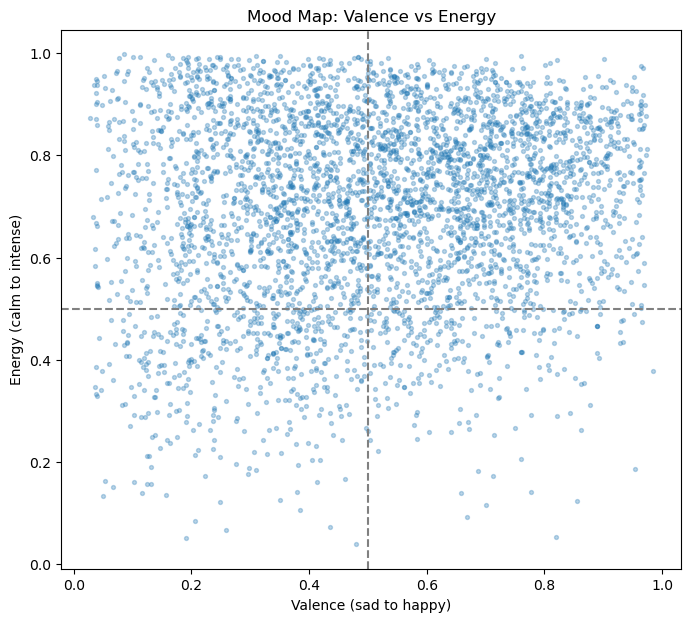

In [5]:
import matplotlib.pyplot as plt

# sample so its not too crowded
sample = songs.sample(4000, random_state=42)

plt.figure(figsize=(8, 7))
plt.scatter(sample["valence"], sample["energy"], s=8, alpha=0.3)
plt.axhline(0.5, color="gray", ls="--")
plt.axvline(0.5, color="gray", ls="--")
plt.xlabel("Valence (sad to happy)")
plt.ylabel("Energy (calm to intense)")
plt.title("Mood Map: Valence vs Energy")
plt.show()

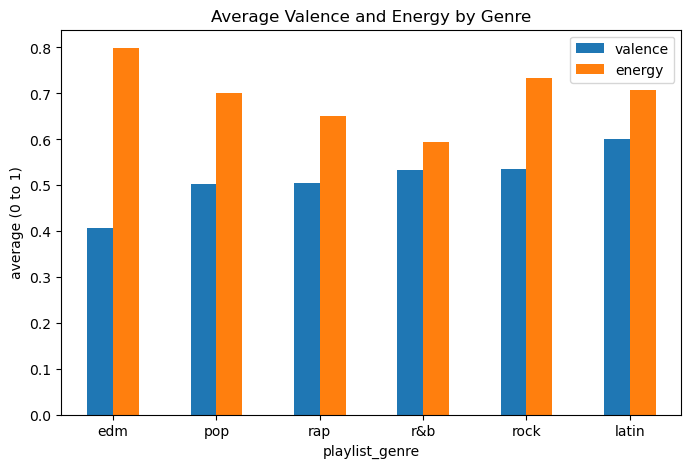

In [6]:
avg = by_genre.groupby("playlist_genre")[["valence", "energy"]].mean().sort_values("valence")

avg.plot(kind="bar", figsize=(8, 5))
plt.ylabel("average (0 to 1)")
plt.title("Average Valence and Energy by Genre")
plt.xticks(rotation=0)
plt.show()

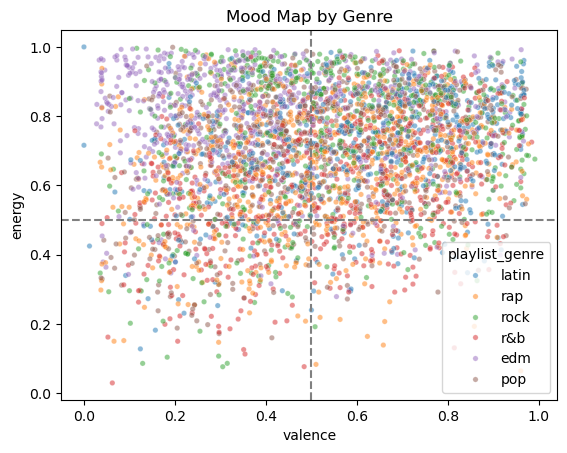

In [7]:
import seaborn as sns

sns.scatterplot(data=by_genre.sample(4000, random_state=42),
                x="valence", y="energy", hue="playlist_genre", alpha=0.5, s=15)
plt.axhline(0.5, color="gray", ls="--")
plt.axvline(0.5, color="gray", ls="--")
plt.title("Mood Map by Genre")
plt.show()

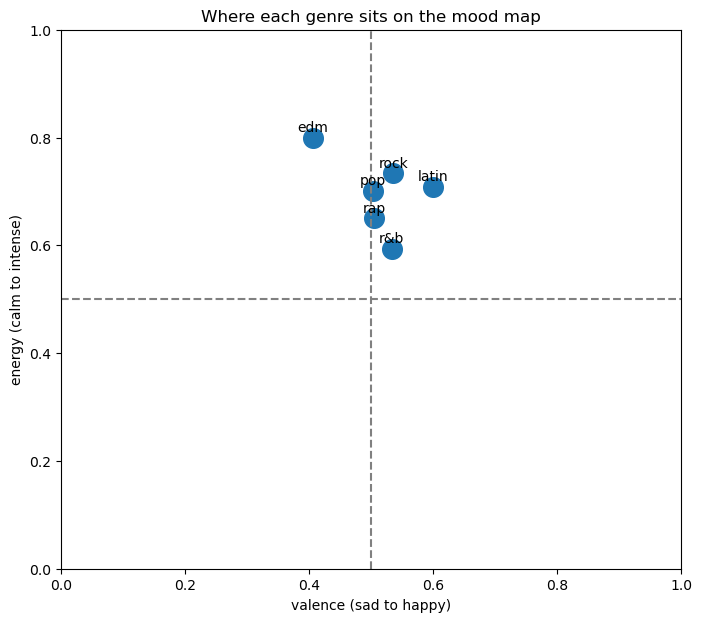

In [8]:
genre_avg = by_genre.groupby("playlist_genre")[["valence", "energy"]].mean()

plt.figure(figsize=(8, 7))
plt.scatter(genre_avg["valence"], genre_avg["energy"], s=200)
for name, row in genre_avg.iterrows():
    plt.text(row["valence"], row["energy"] + 0.012, name, ha="center")
plt.axhline(0.5, color="gray", ls="--")
plt.axvline(0.5, color="gray", ls="--")
plt.xlim(0, 1); plt.ylim(0, 1)
plt.xlabel("valence (sad to happy)")
plt.ylabel("energy (calm to intense)")
plt.title("Where each genre sits on the mood map")
plt.show()

## More EDA: Mood groups and finding songs



                      songs  percent
mood                                
Positive + energetic  13226     46.6
Positive + calm        1493      5.3
Negative + energetic  10811     38.1
Negative + calm        2826     10.0


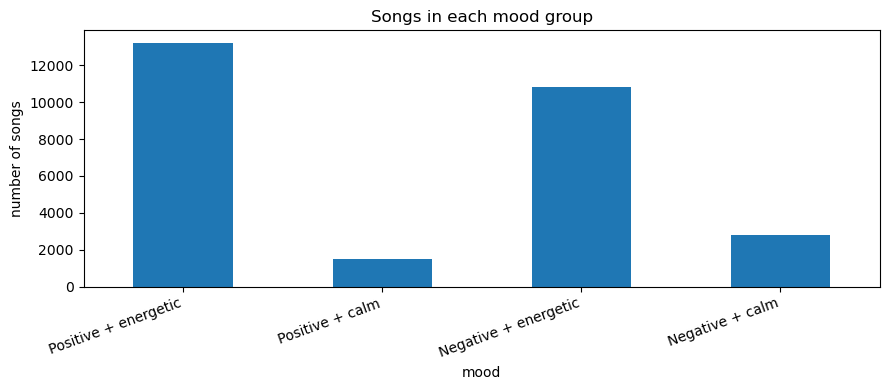

In [9]:
def get_mood(row):
    if row["valence"] >= 0.5:
        if row["energy"] >= 0.5:
            return "Positive + energetic"
        return "Positive + calm"
    if row["energy"] >= 0.5:
        return "Negative + energetic"
    return "Negative + calm"

songs["mood"] = songs.apply(get_mood, axis=1)
by_genre["mood"] = by_genre.apply(get_mood, axis=1)

moods = ["Positive + energetic", "Positive + calm", "Negative + energetic", "Negative + calm"]
mood_counts = songs["mood"].value_counts().reindex(moods)
mood_percent = (mood_counts / len(songs) * 100).round(1)

print(pd.DataFrame({"songs": mood_counts, "percent": mood_percent}))
mood_counts.plot(kind="bar", figsize=(9, 4))
plt.ylabel("number of songs")
plt.title("Songs in each mood group")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

mood            Positive + energetic  Positive + calm  Negative + energetic  \
playlist_genre                                                                
edm                             32.5              1.1                  63.6   
latin                           63.0              4.1                  27.0   
pop                             46.2              3.6                  39.9   
r&b                             45.4             10.7                  24.4   
rap                             45.6              6.8                  36.3   
rock                            50.4              4.7                  35.3   

mood            Negative + calm  
playlist_genre                   
edm                         2.9  
latin                       5.9  
pop                        10.3  
r&b                        19.5  
rap                        11.3  
rock                        9.6  


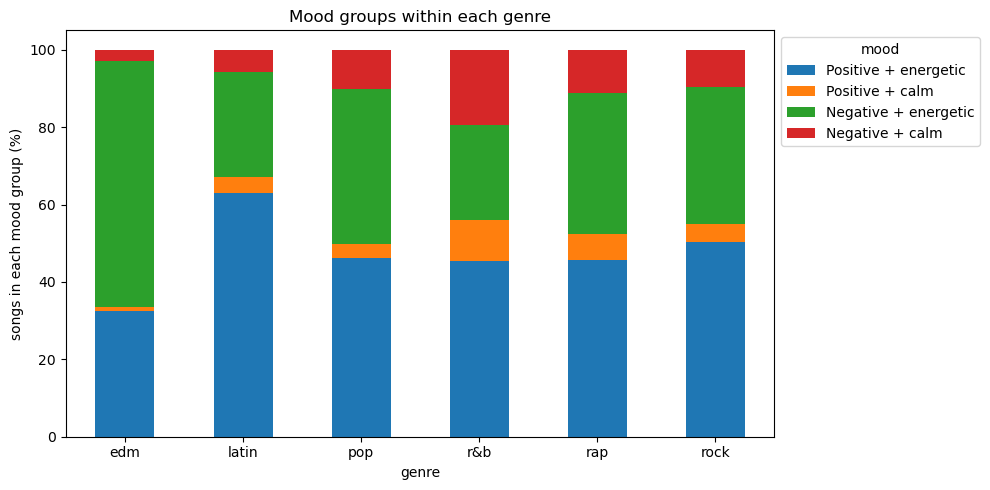

In [10]:
genre_moods = pd.crosstab(by_genre["playlist_genre"], by_genre["mood"], normalize="index") * 100

print(genre_moods[moods].round(1))
genre_moods[moods].plot(kind="bar", stacked=True, figsize=(10, 5))
plt.ylabel("songs in each mood group (%)")
plt.xlabel("genre")
plt.title("Mood groups within each genre")
plt.xticks(rotation=0)
plt.legend(title="mood", bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show()

In [11]:
print(songs.groupby("mood")["track_popularity"].agg(["count", "mean", "median"]).reindex(moods).round(1))

chosen_mood = "Positive + calm"
chosen_genre = "pop"

matches = by_genre[(by_genre["mood"] == chosen_mood) & (by_genre["playlist_genre"] == chosen_genre)]
matches = matches.dropna(subset=["track_name", "track_artist"])

print("matching songs:", len(matches))
matches[["track_name", "track_artist", "track_popularity", "valence", "energy"]].sort_values("track_popularity", ascending=False).head(10)

                      count  mean  median
mood                                     
Positive + energetic  13226  39.5    43.0
Positive + calm        1493  40.4    44.0
Negative + energetic  10811  38.0    40.0
Negative + calm        2826  43.0    47.0
matching songs: 185


,track_name,track_artist,track_popularity,valence,energy
711,Memories,Maroon 5,98,0.575,0.320
344,bad guy,Billie Eilish,95,0.562,0.425
1224,Yellow Hearts,Ant Saunders,89,0.695,0.438
1784,Without Me,Halsey,88,0.533,0.488
1761,Sunflower - Spider-Man: Into the Spider-Verse,Post Malone,88,0.913,0.479
1557,If The World Was Ending (feat. Julia Michaels),JP Saxe,88,0.604,0.473
1247,Liar,Camila Cabello,87,0.652,0.498
5264,all the good girls go to hell,Billie Eilish,86,0.569,0.444
1872,Going Bad (feat. Drake),Meek Mill,85,0.544,0.496
43,bad guy (with Justin Bieber),Billie Eilish,83,0.680,0.453


## More EDA: For mood over time

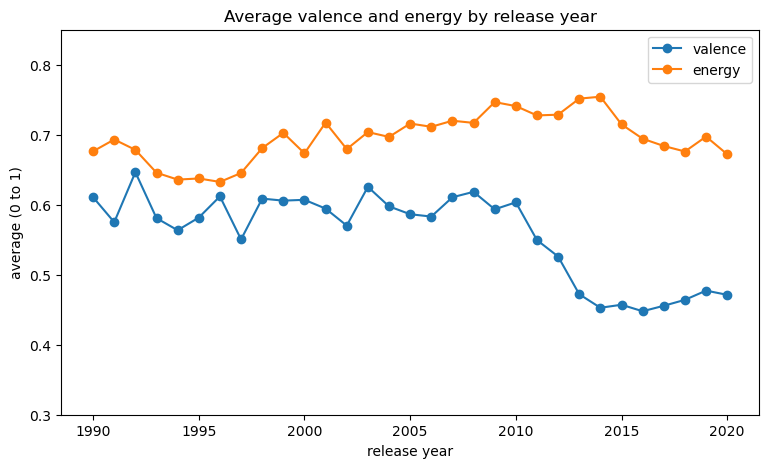

In [12]:
# grab the year out of the release date
songs["year"] = pd.to_datetime(songs["track_album_release_date"], errors="coerce").dt.year

# average valence and energy for each year, only keeping years with enough songs
yearly = songs.dropna(subset=["year"]).groupby("year").agg(
    valence=("valence", "mean"),
    energy=("energy", "mean"),
    n=("track_id", "size"),
)
yearly = yearly[(yearly["n"] >= 100) & (yearly.index >= 1990) & (yearly.index <= 2020)]

yearly[["valence", "energy"]].plot(figsize=(9, 5), marker="o")
plt.ylabel("average (0 to 1)")
plt.xlabel("release year")
plt.title("Average valence and energy by release year")
plt.ylim(0.3, 0.85)
plt.show()

so i wanted to see if the mood of music actually changed over the years. valence stays around 0.60 from the 90s till about 2012 and then it just drops to like 0.47 and kind of stays there, but energy stays high the whole time. so basically songs got sadder but kept their energy, more like negative + energetic after 2013. the main thing to keep in mind is that most of the data is 2010s songs so the older years have way fewer songs to average over.

In [13]:
# checking if popularity actually has anything to do with the audio features
feats = ["valence", "energy", "danceability", "acousticness", "tempo", "loudness"]
print(songs[feats + ["track_popularity"]].corr()["track_popularity"].round(3))

valence             0.023
energy             -0.104
danceability        0.047
acousticness        0.092
tempo               0.004
loudness            0.037
track_popularity    1.000
Name: track_popularity, dtype: float64


i also wanted to check if popularity actually relates to any of the audio features and it basically doesnt, everything is super close to 0 (energy is the strongest and its only -0.10). so what makes a song popular isnt really about how it sounds, its probably stuff thats not even in the data like the artist or what playlist its on. thats kind of why my app lets you filter by mood and look past popularity instead of just going for the popular ones.

## How much does genre actually explain?

In [ ]:
# how much of the mood does genre actually explain
def genre_explains(feat):
    grand = by_genre[feat].mean()
    total = ((by_genre[feat] - grand) ** 2).sum()
    between = by_genre.groupby("playlist_genre")[feat].apply(lambda x: len(x) * (x.mean() - grand) ** 2).sum()
    return round(between / total * 100, 1)

for feat in ["valence", "energy", "danceability", "acousticness"]:
    print(feat, ":", genre_explains(feat), "% explained by genre")

so this checks how much of a song's mood genre actually explains. genre only explains about 6% of valence and 13% of energy, so around 90% of how a song feels is variation within the same genre and not between genres. this is the main reason my app uses mood instead of genre, because genre barely tells you the vibe.

## Does the similar songs finder actually work?

In [ ]:
# check the similar songs finder picks close songs and not random ones
import numpy as np

feel_feats = ["valence", "energy", "danceability", "acousticness", "loudness", "tempo", "speechiness"]
named = songs.dropna(subset=["track_name", "track_artist"]).reset_index(drop=True)
Z = (named[feel_feats] - named[feel_feats].mean()) / named[feel_feats].std()

def closeness_vs_random(name):
    i = named.index[named["track_name"].str.lower() == name.lower()][0]
    d = (((Z - Z.loc[i]) ** 2).sum(axis=1)) ** 0.5
    matches = d[d.index != i].sort_values().iloc[:8].index
    rng = np.random.RandomState(0).choice(named.index, 1000)
    gap_match = np.abs(Z.loc[matches].values - Z.loc[i].values).mean()
    gap_rand = np.abs(Z.loc[rng].values - Z.loc[i].values).mean()
    return round(gap_rand / gap_match, 1)

for name in ["Blinding Lights", "Someone You Loved", "bad guy"]:
    print(name, ":", closeness_vs_random(name), "x closer than random")

this checks whether the similar songs finder actually works. for a few songs i compared how close its top 8 matches are in the audio features vs 1000 random songs. the matches come out around 4 to 6 times closer than random, so the finder is really picking songs that feel alike and not just guessing.